# **TP5 | Modes de chiffrement**

On va utiliser des images BMP parce que les données binaires de ce format correspond directement aux données des pixels (ce n'est pas le cas pour d'autres formats).

La [structure de ces fichiers](https://upload.wikimedia.org/wikipedia/commons/7/75/BMPfileFormat.svg) consiste en une en-tête suivie des données de pixels. Le code `aesbmp.py` contient une classe `CipherFriendlyBmpImage` qui aide à manipuler ces fichiers.
La fonction `main()` de ce fichier contient l'exemple d'utilisation de cette classe qui a servi à chiffrer l'image `ciph-ecb.bmp` fournie.

L'objectif de ce TP est de déchiffrer cette image, pour ensuite comparer d'autres modes de chiffrement plus appropriés.

In [1]:
import os
from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes
from cryptography.hazmat.primitives import padding

from aesbmp import CipherFriendlyBmpImage

## 5.1. Mode de chiffrement ECB

Le mode de chiffrement utilisé est le [mode ECB](https://en.wikipedia.org/wiki/Block_cipher_mode_of_operation#Electronic_codebook_(ECB)) (Electronic Code Book), où chaque bloc est chiffré de la même manière.

![](chiffrement-ecb.svg)

En pratique, ce mode de chiffrement est vivement déconseillé, vu qu'il présente de nombreuses failles (par exemple les défis [12](https://cryptopals.com/sets/2/challenges/12), [13](https://cryptopals.com/sets/2/challenges/13) et [14](https://cryptopals.com/sets/2/challenges/14) de Cryptopals).

### 5.1.a. Observation de l'image chiffrée

**TODO**\
Observer l'image chiffrée `ciph-ecb.bmp` fournie. Arrivez-vous à distinguer des contours de l'image originale ? Est-ce un problème de sécurité ? Pourquoi ?

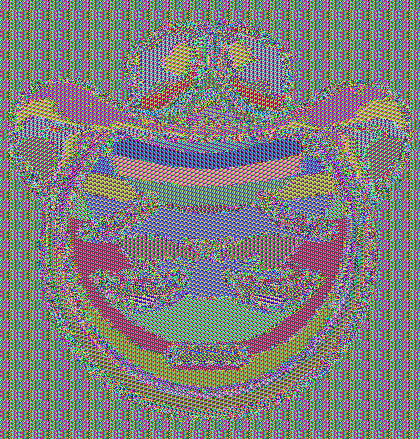

In [2]:
bmp = CipherFriendlyBmpImage.open("cipher-ecb.bmp")
bmp.img

### 5.1.b. Déchiffrement de l'image

**TODO**  
Compléter la fonction `decrypt_aes_ecb` ci-dessous qui inverse la fonction `encrypt_aes_ecb` du fichier compagnon `aesbmp.py`, puis s'en servir pour déchiffrer l'image `ciph-ecb.bmp`.

/tmp/ipykernel_49442/2814899634.py:24: UserWarning: Input data is shorter than the image pixel data. Some bytes have been deleted.
  clear_bmp.frombytes(decrypt_aes_ecb(bmp.tobytes(), key))


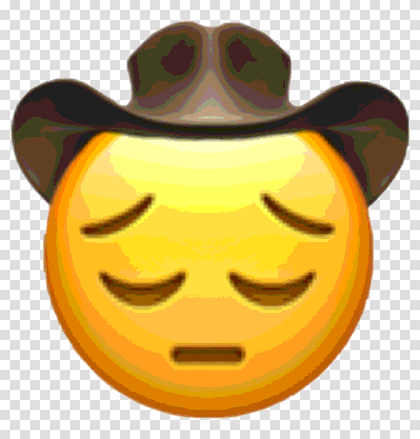

In [5]:
def decrypt_aes_ecb(data: bytes, key: bytes) -> bytes:
    """
    Déchiffre les données avec l'algorithme AES en mode ECB.

    Args:
        data (bytes): données à déchiffrer
        key (bytes): clé de chiffrement (16, 24 ou 32 bytes)
    Returns:
        bytes: données déchiffrées
    """
    cipher = Cipher(algorithms.AES(key), modes.ECB())
    
    decryptor = cipher.decryptor()
    
    padded_data = decryptor.update(data) + decryptor.finalize()

    unpadder = padding.PKCS7(algorithms.AES.block_size).unpadder()
    clear_data = unpadder.update(padded_data) + unpadder.finalize()
    return clear_data


key = b"ALL THEM WITCHES"
clear_bmp = bmp.copy()
clear_bmp.frombytes(decrypt_aes_ecb(bmp.tobytes(), key))
clear_bmp.save("clear-ecb.bmp")
clear_bmp.img

## 5.2. Mode de chiffrement CBC

Un autre mode de chiffrement plus robuste (mais pas encore idéal) est le mode CBC :

![](chiffrement-cbc.svg)

Comme on le voit, celui-ci commence à partir d'une valeur initiale $IV$ aléatoire qui doit être de la même taille que les blocs. Ce mode est implémenté dans `cryptography`.

### 5.2.a. Chiffrer

**TODO**\
Compléter la fonction `encrypt_aes_cbc` ci-dessous.

In [17]:
def encrypt_aes_cbc(data: bytes, key: bytes, iv: bytes) -> bytes:
    """
    Chiffre les données avec l'algorithme AES en mode CBC.

    Args:
        data (bytes): données à chiffrer
        key (bytes): clé de chiffrement (16, 24 ou 32 bytes)
        iv (bytes): vecteur d'initialisation (16 bytes)
    Returns:
        bytes: données chiffrées
    """
    cipher = Cipher(algorithms.AES(key), modes.CBC(iv))
    encryptor = cipher.encryptor()

    padder = padding.PKCS7(algorithms.AES.block_size).padder()
    padded_data = padder.update(data) + padder.finalize()

    return encryptor.update(padded_data) + encryptor.finalize()


"""
iv = os.urandom(16)
cbc_bmp = clear_bmp.copy()
cbc_bmp.frombytes(encrypt_aes_cbc(clear_bmp.tobytes(), key, iv))
cbc_bmp.img
"""

'\niv = os.urandom(16)\ncbc_bmp = clear_bmp.copy()\ncbc_bmp.frombytes(encrypt_aes_cbc(clear_bmp.tobytes(), key, iv))\ncbc_bmp.img\n'

### 5.2.b. Test de la fonction

**TODO**\
Chiffrer des données vides (qui ne contiendront que le *padding*). Est-ce que le résultat contient l'IV ?

In [ ]:
data = b""
key = b"ALL THEM WITCHES"
iv = b"YELLOW SUBMARINE"

ciphertext = encrypt_aes_cbc(data, key, iv)
assert len(ciphertext) == algorithms.AES.block_size // 8
print(f"Données chiffrées : {ciphertext.hex()}")
print(f"Taille du résultat : {len(ciphertext)} octets")
print(f"Taille de l'IV : {len(iv)} octets")
print("Réponse : l'IV n'est pas inclus dans le résultat, il est fourni séparément de la fonction.")

Données chiffrées : 78357d7b0bf99861cafe6a702521a8d3
Taille du résultat : 16 octets
Taille de l'IV : 16 octets
L'IV n'est pas inclus dans le résultat : il est fourni séparément à la fonction.


### 5.2.c. Chiffrement d'une image

**TODO**
- Chiffrer l'image obtenue précédemment avec ce nouveau mode (on pourra utiliser `os.urandom` pour générer une IV).
- Sauvegarder le résultat dans un fichier `mycbc.bmp`.
- Sauvegarder l'IV dans un fichier `iv.bin` pour pouvoir déchiffrer l'image plus tard.

Est-ce que le résultat obtenu semble plus convaincant ?

/home/marietiers/Documents/IT/BUT_IT_S3/R3-09_crypto/TP5 - Modes de chiffrement-20261007/aesbmp.py:87: UserWarning: Not all pixels are stored in the `img` attribute, there might be a padding only available in the raw data.
  warnings.warn(


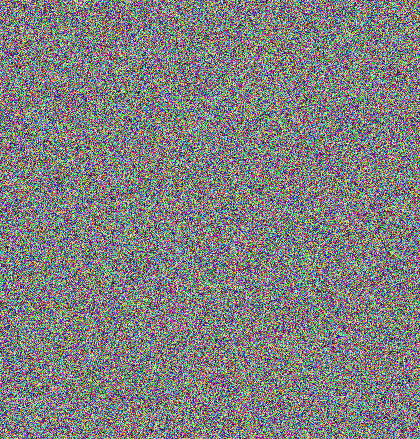

In [13]:
bmp = CipherFriendlyBmpImage.open("clear-ecb.bmp")

key = b"ALL THEM WITCHES"
iv = os.urandom(16)
cipher_data = encrypt_aes_cbc(bmp.tobytes(), key, iv)

cipher_bmp = bmp.copy()
cipher_bmp.frombytes(cipher_data)
cipher_bmp.save("mycbc.bmp")

with open("myiv.bin", "wb") as f:
    f.write(iv)
    
cipher_bmp.img

### 5.2.d. Déchiffrement

**TODO**
- Compléter la fonction `decrypt_aes_cbc` ci-dessous qui inverse la fonction `encrypt_aes_cbc` précédente.
- S'en servir pour déchiffrer l'image `cipher-cbc.bmp` avec l'IV dans `iv-cbc.bin`.

In [ ]:
def decrypt_aes_cbc(data: bytes, key: bytes, iv: bytes) -> bytes:
    """
    Déchiffre les données avec l'algorithme AES en mode CBC.

    Args:
        data (bytes): données à déchiffrer
        key (bytes): clé de chiffrement (16, 24 ou 32 bytes)
    Returns:
        bytes: données déchiffrées
    """
    pass  # TODO

## Pour aller plus loin

### Comparaison entre le mode CBC "à la main" et celui qui utilise `cryptography`

In [ ]:
def encrypt_aes_cbc_handmade(data: bytes, key: bytes, iv: bytes):
    """
    Chiffre les données avec l'algorithme AES en mode CBC, en utilisant
    `cryptography` seulement avec le mode ECB.

    Args:
        data (bytes): données à chiffrer
        key (bytes): clé de chiffrement (16, 24 ou 32 bytes)
        iv (bytes): vecteur d'initialisation (16 bytes)
    Returns:
        bytes: données chiffrées
    """
    cipher = Cipher(algorithms.AES(key), modes.ECB())
    pass  # TODO


data = "Quelques données (texte) à chiffrer.".encode()
key = b"ALL THEM WITCHES"
iv = ...

ref_cbc = encrypt_aes_cbc(data, key, iv)
hand_cbc = encrypt_aes_cbc_handmade(data, key, iv)

print(ref_cbc == hand_cbc)